In [10]:
import os
import cv2
import numpy as np
import matplotlib.pyplot as plt

# Paths (relative to this notebook)
RAW_DIR = "data"               # images directly inside this folder
PROCESSED_DIR = "processed_images"

# Preprocessing settings
TARGET_SIZE = (224, 224)       # (width, height)
COLOR_MODE = "RGB"             # "RGB", "GRAY", or "BGR"
CROP_CENTER = (200, 200)       # or None
NORMALIZE = True

print("Current working directory:", os.getcwd())
print("Raw data dir exists:", os.path.exists(RAW_DIR))
print("Processed dir will be created at:", PROCESSED_DIR)


Current working directory: /Users/aakashjawle/Desktop/IITB/Week 2/Day 1
Raw data dir exists: True
Processed dir will be created at: processed_images


In [11]:
from typing import Tuple, Optional

def preprocess_for_training(
    img: np.ndarray,
    target_size: Tuple[int, int] = (224, 224),
    color_mode: str = "RGB",
    crop_center: Optional[Tuple[int, int]] = None,
    normalize: bool = True
) -> np.ndarray:
    """
    Basic preprocessing pipeline for training images.

    Steps:
    1. Optional center crop.
    2. Resize to target size.
    3. Convert color space (BGR → RGB/GRAY).
    4. Normalize pixel values to [0, 1].

    Parameters
    ----------
    img : np.ndarray
        Image read using cv2.imread() in BGR format.
    target_size : (int, int)
        (width, height)
    color_mode : str
        "RGB", "BGR" or "GRAY".
    crop_center : (int, int) or None
        Optional center crop size (crop_h, crop_w).
    normalize : bool
        If True, scale values to [0, 1].

    Returns
    -------
    np.ndarray
        Preprocessed image.
    """

    # 1️⃣ Optional center crop
    if crop_center is not None:
        crop_h, crop_w = crop_center
        h, w = img.shape[:2]

        crop_h = min(crop_h, h)
        crop_w = min(crop_w, w)

        start_y = (h - crop_h) // 2
        start_x = (w - crop_w) // 2
        img = img[start_y:start_y + crop_h, start_x:start_x + crop_w]

    # 2️⃣ Resize
    target_w, target_h = target_size
    img = cv2.resize(img, (target_w, target_h), interpolation=cv2.INTER_AREA)

    # 3️⃣ Color conversion
    if color_mode.upper() == "RGB":
        img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
    elif color_mode.upper() == "GRAY":
        img = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
    # if BGR → nothing to change

    # 4️⃣ Normalize
    if normalize:
        img = img.astype(np.float32) / 255.0

    return img


def process_flat_folder(
    input_root,
    output_root,
    target_size=(224, 224),
    color_mode="RGB",
    crop_center=(200, 200),
    normalize=True,
    save_as="png"
):
    """
    Process all images directly inside 'input_root' and save them
    into 'output_root' with the same filenames (but possibly new extension).
    """
    os.makedirs(output_root, exist_ok=True)

    img_files = [
        f for f in os.listdir(input_root)
        if f.lower().endswith((".jpg", ".jpeg", ".png", ".bmp", ".tif", ".tiff"))
    ]

    print(f"Found {len(img_files)} images in '{input_root}'")

    for fname in img_files:
        in_path = os.path.join(input_root, fname)
        img = cv2.imread(in_path)

        if img is None:
            print("Skipping unreadable file:", in_path)
            continue

        processed = preprocess_for_training(
            img,
            target_size=target_size,
            color_mode=color_mode,
            crop_center=crop_center,
            normalize=normalize
        )

        # Convert normalized float image back to uint8 for saving
        save_img = processed
        if normalize:
            save_img = (processed * 255.0).clip(0, 255).astype(np.uint8)

        # If we worked in RGB, convert back to BGR for cv2.imwrite
        if color_mode.upper() == "RGB":
            save_img = cv2.cvtColor(save_img, cv2.COLOR_RGB2BGR)

        base_name = os.path.splitext(fname)[0]
        out_path = os.path.join(output_root, f"{base_name}.{save_as}")

        cv2.imwrite(out_path, save_img)

    print(f"✅ Finished processing. Saved images to '{output_root}'")


In [12]:
# List image files directly inside RAW_DIR
image_files = [
    f for f in os.listdir(RAW_DIR)
    if f.lower().endswith((".jpg", ".jpeg", ".png", ".bmp", ".tif", ".tiff"))
]

print("Number of images found in data/:", len(image_files))
print("First few images:", image_files[:5])

if len(image_files) == 0:
    raise ValueError(f"No images found in '{RAW_DIR}'. Please put some images there.")

sample_file = image_files[0]
sample_path = os.path.join(RAW_DIR, sample_file)

print("Sample image selected:", sample_file)
print("Sample full path:", sample_path)


Number of images found in data/: 5
First few images: ['healthy102_.jpg', 'healthy103_.jpg', 'healthy110_.jpg', 'healthy107_.jpg', 'healthy111_.jpg']
Sample image selected: healthy102_.jpg
Sample full path: data/healthy102_.jpg


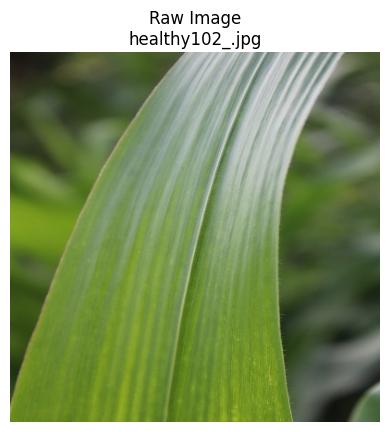

Raw image shape (H, W, C): (400, 400, 3)
Raw dtype: uint8
Raw pixel range: min = 12 max = 226


In [13]:
# Read sample image in BGR (OpenCV default)
img_bgr = cv2.imread(sample_path)
if img_bgr is None:
    raise ValueError("Failed to read the sample image. Check the file path and format.")

# Convert to RGB for displaying using matplotlib
img_rgb = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2RGB)

plt.imshow(img_rgb)
plt.title(f"Raw Image\n{sample_file}")
plt.axis("off")
plt.show()

print("Raw image shape (H, W, C):", img_bgr.shape)
print("Raw dtype:", img_bgr.dtype)
print("Raw pixel range: min =", img_bgr.min(), "max =", img_bgr.max())


Processed shape: (224, 224, 3)
Processed dtype: float32
Processed pixel range: min = 0.078431375 max = 0.85490197


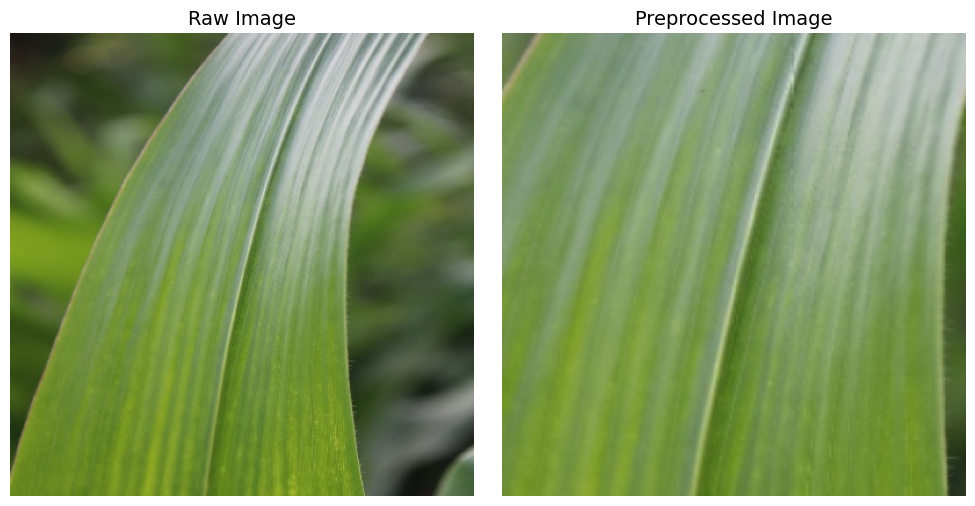

In [17]:
# Compute the processed image AND show side-by-side in one go

# 1) Run preprocessing
processed = preprocess_for_training(
    img=img_bgr,
    target_size=TARGET_SIZE,
    color_mode=COLOR_MODE,
    crop_center=CROP_CENTER,
    normalize=NORMALIZE
)

print("Processed shape:", processed.shape)
print("Processed dtype:", processed.dtype)
print("Processed pixel range: min =", processed.min(), "max =", processed.max())

# 2) Plot raw vs preprocessed
fig, axes = plt.subplots(1, 2, figsize=(10, 5))

# Left: Raw
axes[0].imshow(img_rgb)
axes[0].set_title("Raw Image", fontsize=14)
axes[0].axis("off")

# Right: Preprocessed
if COLOR_MODE.upper() == "RGB":
    show_img = processed
    axes[1].imshow(show_img)
elif COLOR_MODE.upper() == "GRAY":
    show_img = processed
    axes[1].imshow(show_img, cmap="gray")
else:  # BGR => convert to RGB for display
    show_img = cv2.cvtColor(processed, cv2.COLOR_BGR2RGB)
    axes[1].imshow(show_img)

axes[1].set_title("Preprocessed Image", fontsize=14)
axes[1].axis("off")

plt.tight_layout()
plt.show()


In [18]:
process_flat_folder(
    input_root=RAW_DIR,
    output_root=PROCESSED_DIR,
    target_size=TARGET_SIZE,
    color_mode=COLOR_MODE,
    crop_center=CROP_CENTER,
    normalize=NORMALIZE,
    save_as="png"
)


Found 5 images in 'data'
✅ Finished processing. Saved images to 'processed_images'


Number of processed images: 5
Sample processed filename: healthy102_.png


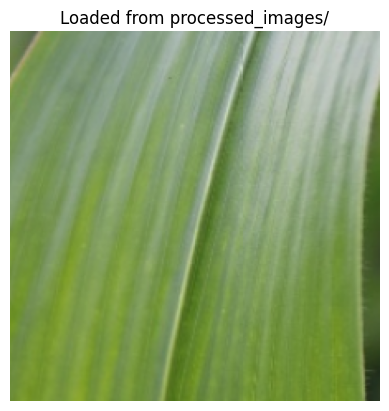

Processed (disk) shape: (224, 224, 3)
Processed (disk) dtype: uint8
Processed (disk) pixel range: min = 20 max = 218


In [19]:
processed_files = [
    f for f in os.listdir(PROCESSED_DIR)
    if f.lower().endswith((".jpg", ".jpeg", ".png", ".bmp", ".tif", ".tiff"))
]

print("Number of processed images:", len(processed_files))
print("Sample processed filename:", processed_files[0])

proc_path = os.path.join(PROCESSED_DIR, processed_files[0])
proc_bgr = cv2.imread(proc_path)

if proc_bgr is None:
    raise ValueError("Failed to read processed image from disk.")

# Show correctly depending on color mode
if COLOR_MODE.upper() == "RGB":
    proc_show = cv2.cvtColor(proc_bgr, cv2.COLOR_BGR2RGB)
    cmap = None
elif COLOR_MODE.upper() == "GRAY":
    proc_show = proc_bgr
    cmap = "gray"
else:
    proc_show = cv2.cvtColor(proc_bgr, cv2.COLOR_BGR2RGB)
    cmap = None

plt.imshow(proc_show, cmap=cmap)
plt.title("Loaded from processed_images/")
plt.axis("off")
plt.show()

print("Processed (disk) shape:", proc_bgr.shape)
print("Processed (disk) dtype:", proc_bgr.dtype)
print("Processed (disk) pixel range: min =", proc_bgr.min(), "max =", proc_bgr.max())


## Observations – Day 1

### Raw Image Characteristics
- Images were of different sizes and resolutions.
- Pixel values originally in the range **0–255** (dtype = uint8).
- Background and noise visible in some parts of the image.

### Preprocessing Steps Applied
1. **Center Crop** → Removed unwanted borders, focused on leaf section.
2. **Resize to 224×224** → Uniform input dimensions for model training.
3. **Color Conversion** → BGR → RGB for correct visualization & model input.
4. **Normalization** → Pixel values scaled to **[0, 1]** (dtype = float32).

### Impact of Preprocessing
- All images now have consistent shape: **(224, 224, 3)**.
- Normalized images show smoother gradients → better model convergence.
- Reduced noise & variability, which helps the model learn features better.
- Preprocessed images are successfully saved under `processed_images/`.

### Conclusion
✔ A complete reusable preprocessing pipeline for model training is working.  
✔ Day 1 deliverables complete:  
    - `Day1.ipynb`  
    - `processed_images` folder  
    - `preprocess_for_training.py` (copy same functions to it)

Re
